# FILTRO DE KALMAN PARA FILTRAR UNA SEÑAL RUIDOSA
En este ejemplo se utiliza el filtro de Kalman para estimar una señal (filtrar) a partir de mediciones (datos) contaminados con ruido
Modelo del sistema:

$x(k+1)=F\cdot x(k)+w(k)$

$z(k)=H\cdot x(k)+v(k)$

donde:

$x(k)$: Señalruidosa

$z(k)$: Medición ruidosa - datos capturados

$w(k)$: ruido de proceso ~ N(0,Q)

$v(k)$: ruido de medición ~ N(0,R)

## Simulación para generar los datos

In [101]:
import numpy as np

# Parametros de la simulación
T = 10.0
dt = 0.1

# Covarianzas del filtro
Q = 1e-3
R = 0.25
# Generación señal sin ruido (verdadera)
t = np.arange(0,T,dt)
x_real = np.sin(0.5*t) + 0.3 * np.cos(2*t)
# Geneación señal ruidosa
sigma_v = np.sqrt(R)
z = x_real + sigma_v * np.random.randn(len(t))

## Inicialización Filtro de Kalman

In [102]:
# Estado inicial
x_est = 0

# Covarianza inicial
P = 1

# Matrices (modelo escalar)
F = 1
H = 1

# Arreglos de almacenamiento 
x_t = np.zeros(len(t))
P_t = np.zeros(len(t))
K_t = np.zeros(len(t))

## Filtro de Kalman

In [103]:
for k in range(len(t)):

    # Predicción
    x_pred = F * x_est
    P_pred = F * P * F + Q

    # Actualización
    y_m = z[k] - H * x_pred

    # Ganancia de Kalman
    S = H * P_pred * H + R
    K = P_pred * H / S

    # Corrección
    x_est = x_pred + K * y_m

    # Actualización de covarianza
    P = (1-K*H) * P_pred

    #Guardar resultados
    x_t[k] = x_est
    P_t[k] = P
    K_t[k] = K

## Metricas de desempeño

In [104]:
rmse_medicion = np.sqrt(np.mean((z - x_real)**2))
rmse_filtrado = np.sqrt(np.mean((x_t - x_real)**2))

print("RMSE medicion ruidosa : ", rmse_medicion)
print("RMSE señal filtrada : ", rmse_filtrado)

RMSE medicion ruidosa :  0.5119244902873543
RMSE señal filtrada :  0.3621545697863828


## Graficas de resultados

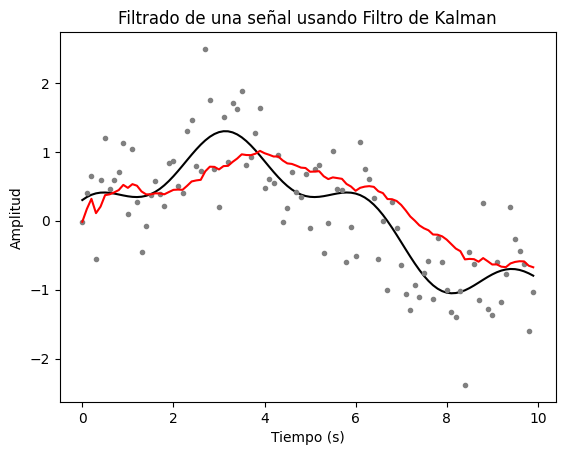

In [106]:
import matplotlib.pyplot as plt

plt.figure(1)
plt.plot(t, x_real, color = 'k')
plt.plot(t,z , '.',color='gray' )
plt.plot(t,x_t, color='r')
plt.title("Filtrado de una señal usando Filtro de Kalman")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")


# plt.figure(2)
# plt.plot(t, K_t, color = 'b')
# plt.xlabel("Tiempo (s)")
# plt.title("Ganancia de Kalman")

# plt.figure(3)
# plt.plot(t, np.sqrt(P_t), color = 'm')
# plt.xlabel("Tiempo (s)")
# plt.title("Incertidumbre de la estimación")

plt.show()